**Downloading the file and inspection**

In [1]:
import pandas as pd

In [2]:
df= pd.read_csv('Supermarket_sales.csv')

In [3]:
df.head()
df.shape
df.info()
df.isna().sum()
df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   sale_id           1000 non-null   int64  
 1   branch            1000 non-null   object 
 2   city              1000 non-null   object 
 3   customer_type     1000 non-null   object 
 4   gender            1000 non-null   object 
 5   product_name      1000 non-null   object 
 6   product_category  1000 non-null   object 
 7   unit_price        1000 non-null   float64
 8   quantity          1000 non-null   int64  
 9   tax               1000 non-null   float64
 10  total_price       1000 non-null   float64
 11  reward_points     1000 non-null   int64  
dtypes: float64(3), int64(3), object(6)
memory usage: 93.9+ KB


np.int64(0)

**Verification of figures and calculating logic**

In [4]:
df[["unit_price", "quantity", "tax", "total_price", "reward_points"]].describe()

,unit_price,quantity,tax,total_price,reward_points
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,10.836110,10.337000,7.758010,118.583900,6.057000
std,5.775924,6.029908,6.538066,99.936441,9.350464
min,1.020000,1.000000,0.080000,1.210000,0.000000
25%,5.867500,5.000000,2.510000,38.380000,0.000000
50%,10.615000,10.000000,5.870000,89.705000,0.000000
75%,15.882500,16.000000,11.522500,176.072500,10.000000
max,20.980000,20.000000,28.390000,433.990000,43.000000


In [17]:
round((df["total_price"] - (df["unit_price"] * df["quantity"] + df["tax"])).abs().max(),2)

0.0

**Analyze sales**

In [6]:
df.groupby("city")["total_price"].sum().sort_values(ascending=False).round(2)

,total_price
city,
Chicago,42584.71
New York,40226.93
Los Angeles,35772.26


In [7]:
df.groupby("city")["total_price"].agg(["count", "mean", "sum"]).sort_values("sum", ascending=False).round(2)

,count,mean,sum
city,,,
Chicago,330,129.04,42584.71
New York,344,116.94,40226.93
Los Angeles,326,109.73,35772.26


In [8]:
df.groupby("product_category")["total_price"].agg(["count", "mean", "sum"]).sort_values("sum", ascending=False).round(2)

,count,mean,sum
product_category,,,
Personal Care,208,130.05,27050.18
Fruits,209,125.35,26197.45
Beverages,187,122.91,22983.32
Household,198,109.17,21615.84
Stationery,198,104.73,20737.11


In [9]:
df.groupby("customer_type")["total_price"].agg(["count", "mean", "sum"]).round(2)

,count,mean,sum
customer_type,,,
Member,516,122.51,63213.63
Normal,484,114.40,55370.27


In [10]:
df.groupby("customer_type")["reward_points"].agg(["count", "mean", "sum"]).round(2)

,count,mean,sum
customer_type,,,
Member,516,11.74,6057
Normal,484,0.00,0


In [11]:
df.groupby("gender")["total_price"].agg(["count", "mean", "sum"]).round(2)

,count,mean,sum
gender,,,
Female,472,114.97,54265.45
Male,528,121.82,64318.45


**Creating graphs**

In [12]:
import matplotlib.pyplot as plt

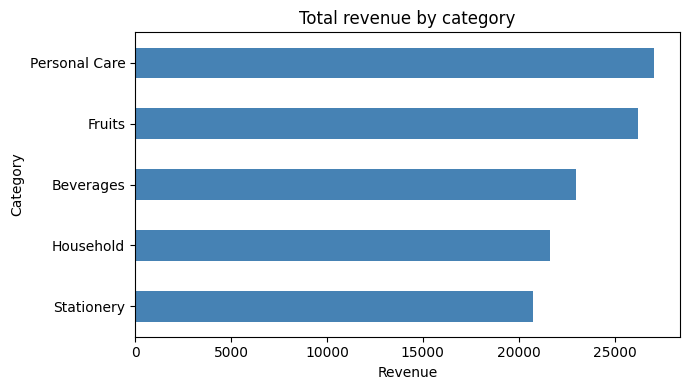

In [13]:
ca_cat = df.groupby("product_category")["total_price"].sum().sort_values()
ca_cat.plot(kind="barh", color="steelblue", figsize=(7, 4))
plt.title("Total revenue by category")
plt.xlabel("Revenue")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig("chart_categories.png")
plt.show()

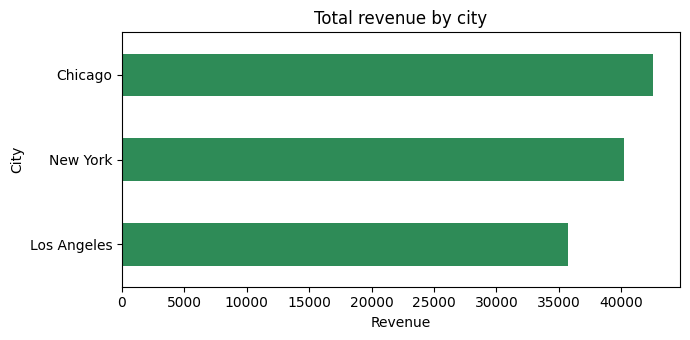

In [14]:
ca_ville = df.groupby("city")["total_price"].sum().sort_values()
ca_ville.plot(kind="barh", color="seagreen", figsize=(7, 3.5))
plt.title("Total revenue by city")
plt.xlabel("Revenue")
plt.ylabel("City")
plt.tight_layout()
plt.savefig("chart_city.png")
plt.show()

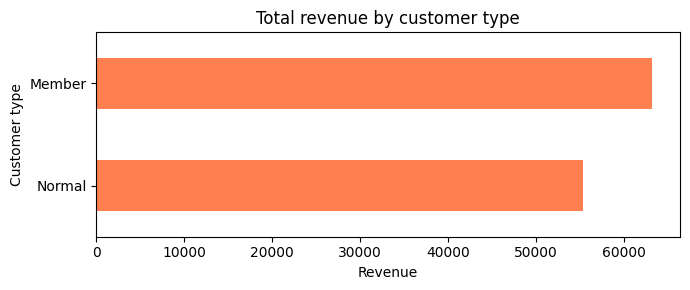

In [15]:
ca_client = df.groupby("customer_type")["total_price"].sum().sort_values()
ca_client.plot(kind="barh", color="coral", figsize=(7, 3))
plt.title("Total revenue by customer type")
plt.xlabel("Revenue")
plt.ylabel("Customer type")
plt.tight_layout()
plt.savefig("re_customer_type.png")
plt.show()